In [1]:
import os
import warnings
import numpy as np
import seaborn as sns
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, precision_score, recall_score, f1_score, roc_auc_score

warnings.filterwarnings("ignore")

## 2a) Construct and Train Deep Learning Model

In [2]:
DATASET_TRAIN = './data/train'
DATASET_TEST = './data/test'

def load_images(dataset_path, img_size=32):
    images = []
    for _, filename in enumerate(os.listdir(dataset_path)):
        path = os.path.join(dataset_path, filename)
        img = tf.io.read_file(path)
        img = tf.image.decode_png(img, channels=3)
        img = tf.image.resize(img, (img_size, img_size))
        img = tf.cast(img, tf.float32) / 255.0
        images.append(img.numpy())
    return np.asarray(images).astype(np.float32)

original_train_images = load_images(DATASET_TRAIN)
original_test_images = load_images(DATASET_TEST)

print(f"Train set shape: {original_train_images.shape}")
print(f"Test set shape:  {original_test_images.shape}")

Train set shape: (500, 32, 32, 3)
Test set shape:  (100, 32, 32, 3)


In [3]:
x_train, x_val = train_test_split(original_train_images, test_size=0.2, random_state=42)
x_test = original_test_images

print(f"x_train shape: {x_train.shape}")
print(f"x_val shape:   {x_val.shape}")
print(f"x_test shape:  {x_test.shape}")

BATCH_SIZE = 64
MAX_EPOCHS = 100
LEARNING_RATE = 1e-3
LATENT_DIMENSION = 32
HIDDEN_DIMENSION = 512
IMAGE_ORIGINAL_SIZE = x_train.shape[1:]
IMAGE_SIZE = IMAGE_ORIGINAL_SIZE[0] * IMAGE_ORIGINAL_SIZE[1] * IMAGE_ORIGINAL_SIZE[2]

x_train shape: (400, 32, 32, 3)
x_val shape:   (100, 32, 32, 3)
x_test shape:  (100, 32, 32, 3)


In [4]:
# model VAE
class VAE(tf.keras.Model):
    def __init__(self, dim, **kwargs):
        super(VAE, self).__init__(**kwargs)
        dim_h = dim[0]
        dim_z = dim[1]

        self.fc1 = tf.keras.layers.Dense(dim_h, activation=tf.nn.relu)
        self.fc2 = tf.keras.layers.Dense(dim_z)
        self.fc3 = tf.keras.layers.Dense(dim_z)
        self.fc4 = tf.keras.layers.Dense(dim_h)
        self.fc5 = tf.keras.layers.Dense(IMAGE_SIZE)

        self.encode_batch_norm = tf.keras.layers.BatchNormalization()
        self.decode_batch_norm = tf.keras.layers.BatchNormalization()

    def encode(self, x):
        x = self.encode_batch_norm(x)
        h = self.fc1(x)
        return self.fc2(h), self.fc3(h)
    
    def decode_logit(self, z):
        h = self.fc4(z)
        h = self.fc5(h)
        return self.decode_batch_norm(h)
    
    def decode(self, z):
        return tf.nn.sigmoid(self.decode_logit(z))
    
    def reparameterize(self, mu, log_var):
        std = tf.exp(0.5 * log_var)
        eps = tf.random.normal(std.shape)
        return mu + std * eps
    
    def call(self, input, training=None, mask=None):
        mu, log_var = self.encode(input)
        z = self.reparameterize(mu, log_var)
        x_recon_logit = self.decode_logit(z)
        return x_recon_logit, mu, log_var

In [5]:
model = VAE((HIDDEN_DIMENSION, LATENT_DIMENSION))
model.build(input_shape=(BATCH_SIZE, IMAGE_SIZE))
print(model.summary())

Model: "vae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

None


In [6]:
optimizers = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)

train_dataset = tf.data.Dataset.from_tensor_slices(x_train)
train_dataset = train_dataset.shuffle(BATCH_SIZE * 5, reshuffle_each_iteration=True).batch(BATCH_SIZE)
val_dataset   = tf.data.Dataset.from_tensor_slices(x_val).batch(BATCH_SIZE)

In [7]:
train_loss_history = []
train_kl_history = []
val_loss_history = []
val_kl_history = []

for epoch in range(MAX_EPOCHS):
    # train
    train_recon_losses = []
    train_kl_losses = []

    for x in train_dataset:
        batch_size = tf.cast(tf.shape(x)[0], tf.float32)
        x = tf.reshape(x, [-1, IMAGE_SIZE])

        with tf.GradientTape() as tape:
            x_recon_logit, mu, log_var = model(x, training=True)
            recon = tf.nn.sigmoid_cross_entropy_with_logits(labels=x, logits=x_recon_logit)
            recon_loss = tf.reduce_sum(recon) / batch_size

            kl_div = -0.5 * tf.reduce_sum(1. + log_var - tf.square(mu) - tf.exp(log_var), axis=1)
            kl_div = tf.reduce_mean(kl_div)

            loss = recon_loss + kl_div

        gradients = tape.gradient(loss, model.trainable_variables)
        gradients = [tf.clip_by_norm(g, 15.0) if g is not None else None for g in gradients]
        optimizers.apply_gradients(zip(gradients, model.trainable_variables))

        train_recon_losses.append(recon_loss.numpy())
        train_kl_losses.append(kl_div.numpy())

    train_recon = np.mean(train_recon_losses)
    train_kl = np.mean(train_kl_losses)
    train_loss = train_recon + train_kl

    train_loss_history.append(train_loss)
    train_kl_history.append(train_kl)

    # validation
    val_recon_losses = []
    val_kl_losses = []

    for x in val_dataset:
        batch_size = tf.cast(tf.shape(x)[0], tf.float32)
        x = tf.reshape(x, [-1, IMAGE_SIZE])
        x_recon_logit, mu, log_var = model(x, training=False)

        recon = tf.nn.sigmoid_cross_entropy_with_logits(labels=x, logits=x_recon_logit)
        recon_loss = tf.reduce_sum(recon) / batch_size

        kl_div_val = -0.5 * tf.reduce_sum(1. + log_var - tf.square(mu) - tf.exp(log_var), axis=1)
        kl_div_val = tf.reduce_mean(kl_div_val)

        val_recon_losses.append(recon_loss.numpy())
        val_kl_losses.append(kl_div_val.numpy())

    val_recon = np.mean(val_recon_losses)
    val_kl = np.mean(val_kl_losses)
    val_loss = val_recon + val_kl

    val_loss_history.append(val_loss)
    val_kl_history.append(val_kl)

    print(
        f"Epoch: {epoch + 1}/{MAX_EPOCHS}, "
        f"train_loss: {train_loss:.6f}, train_kl: {train_kl:.6f}, "
        f"val_loss: {val_loss:.6f}, val_kl: {val_kl:.6f}"
    )

Epoch: 1/100, train_loss: 2384.077148, train_kl: 92.618042, val_loss: 2262.190918, val_kl: 41.736046
Epoch: 2/100, train_loss: 2155.954590, train_kl: 90.503471, val_loss: 2216.160889, val_kl: 21.251253
Epoch: 3/100, train_loss: 2077.775879, train_kl: 75.096062, val_loss: 2235.546875, val_kl: 25.386742
Epoch: 4/100, train_loss: 2038.960205, train_kl: 76.048485, val_loss: 2258.713867, val_kl: 17.020058
Epoch: 5/100, train_loss: 2023.794800, train_kl: 70.641609, val_loss: 2190.574463, val_kl: 15.194129
Epoch: 6/100, train_loss: 2007.596802, train_kl: 65.423561, val_loss: 2174.896729, val_kl: 15.447407
Epoch: 7/100, train_loss: 1990.143555, train_kl: 67.013298, val_loss: 2094.416992, val_kl: 14.735275
Epoch: 8/100, train_loss: 1972.392578, train_kl: 63.187901, val_loss: 2081.995605, val_kl: 13.748018
Epoch: 9/100, train_loss: 1952.065430, train_kl: 62.402748, val_loss: 2092.575928, val_kl: 13.831852
Epoch: 10/100, train_loss: 1953.949097, train_kl: 62.688625, val_loss: 2062.242920, val_kl:

## 2b) Plot Training and Validation Losses Over Epochs

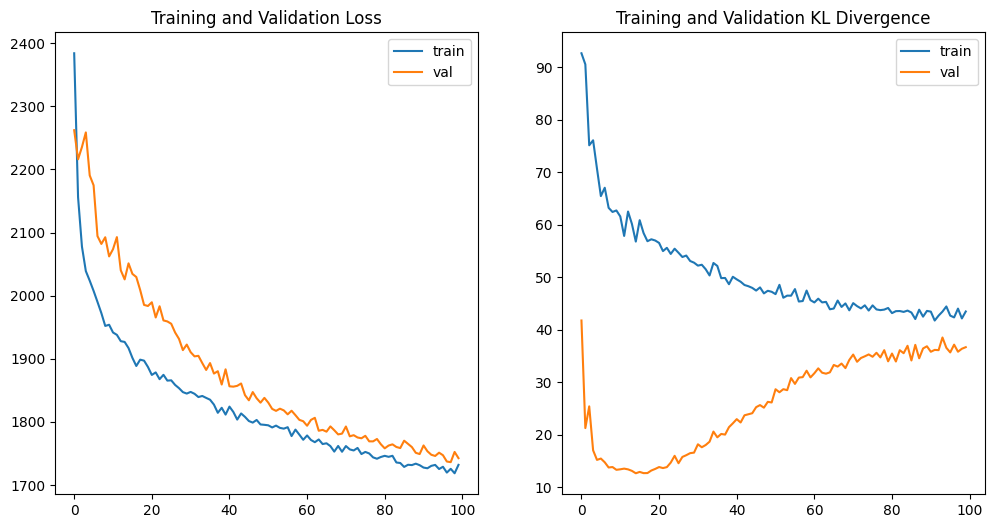

In [8]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title('Training and Validation Loss')
plt.plot(train_loss_history, label='train')
plt.plot(val_loss_history, label='val')
plt.legend()

plt.subplot(1, 2, 2)
plt.title('Training and Validation KL Divergence')
plt.plot(train_kl_history, label='train')
plt.plot(val_kl_history, label='val')
plt.legend()
plt.show()

VAE Loss Analysis
1. Convergence pattern: Kedua loss (training dan validation) menunjukkan penurunan yg konsisten selama epoch awal yang berarti model berhasil belajar pola dari data
2. KL divergence behavior: KL divergence meningkat selama training, yg merupakan perilaku normal dalam VAE. Ini menunjukkan bhw distribusi latent space (mu dan log_var) semakin berbeda dari prior distribution artinya model sedang belajar representasi yg lebih meaningful
3. Ovefitting check: gap antara training dan validation loss relatif kecil yg menandakan model tidak mengalami overfitting signifikan. Model dpt generalize dengan baik pada data yg belum pernah dilihat
4. Reconstruction quality: total loss yg menurun menunjukkan bhw model semakin baik dalam merekonstruksi gambar input, yg berarti decoder mampu menghasilkan gambar yg mirip dengan data asli

## 2c) Generate 500 Images Using the Trained VAE Model

In [9]:
# decode to image
def get_out_from_z(z):
    out = model.decode(z)
    out = tf.reshape(out, (-1, IMAGE_ORIGINAL_SIZE[0], IMAGE_ORIGINAL_SIZE[1], IMAGE_ORIGINAL_SIZE[2]))
    return out

In [10]:
# generate images
NUM_GENERATED_IMAGES = 500

def sample_generated_images(num_images):
    batches = []
    remaining = num_images
    while remaining > 0:
        current = min(remaining, BATCH_SIZE)
        z = tf.random.normal((current, LATENT_DIMENSION))
        batch = get_out_from_z(z)
        batches.append(batch.numpy())
        remaining -= current
    return np.concatenate(batches, axis=0).astype(np.float32)

generated_images = sample_generated_images(NUM_GENERATED_IMAGES)
print(f"Generated images shape: {generated_images.shape}")

Generated images shape: (500, 32, 32, 3)


## 2d) Compare 10 Generated and Original Images

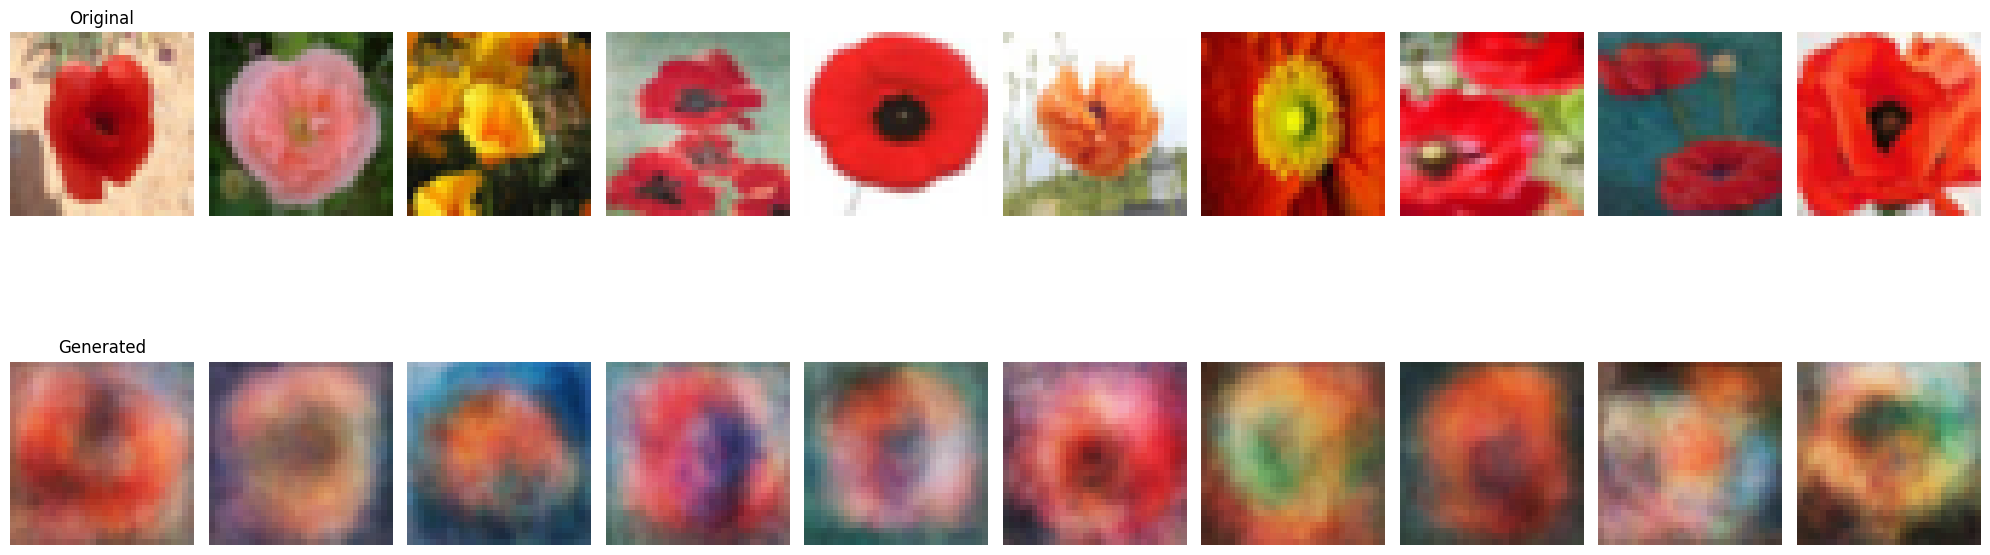

In [ ]:
# visualize original vs generated samples
comparison_count = 10
plt.figure(figsize=(20, 8))
for idx in range(comparison_count):
    ax = plt.subplot(2, comparison_count, idx + 1)
    plt.imshow(original_train_images[idx])
    plt.axis('off')
    if idx == 0:
        ax.set_title('Original')

for idx in range(comparison_count):
    ax = plt.subplot(2, comparison_count, comparison_count + idx + 1)
    plt.imshow(generated_images[idx])
    plt.axis('off')
    if idx == 0:
        ax.set_title('Generated')

plt.tight_layout()
plt.show()

Generated vs Original Images Comparison
1. Color distribution: gambar yang dihasilkan VAE memiliki distribusi warna yg mirip dengan gambar asli meskipun lebih blur atau di smoothing
2. Structural features: VAE berhasil menangkap struktur umum dan bentuk dasar dari objek, namun detail nya menjadi halus
3. Blurriness: gambar generated terlihat lebih blur dibanding original. Ini disebabkan oleh penggunaan reconstruction loss berbasis probabilitas yg menghasilkan average pixel values drpd detail tajam
4. Variability: Meskipun disampling dari distribusi latent yang sama (prior N(0,1)), gambar generated menunjukkan variasi yang cukup, mengindikasikan bahwa model telah belajar latent representation yang diverse.

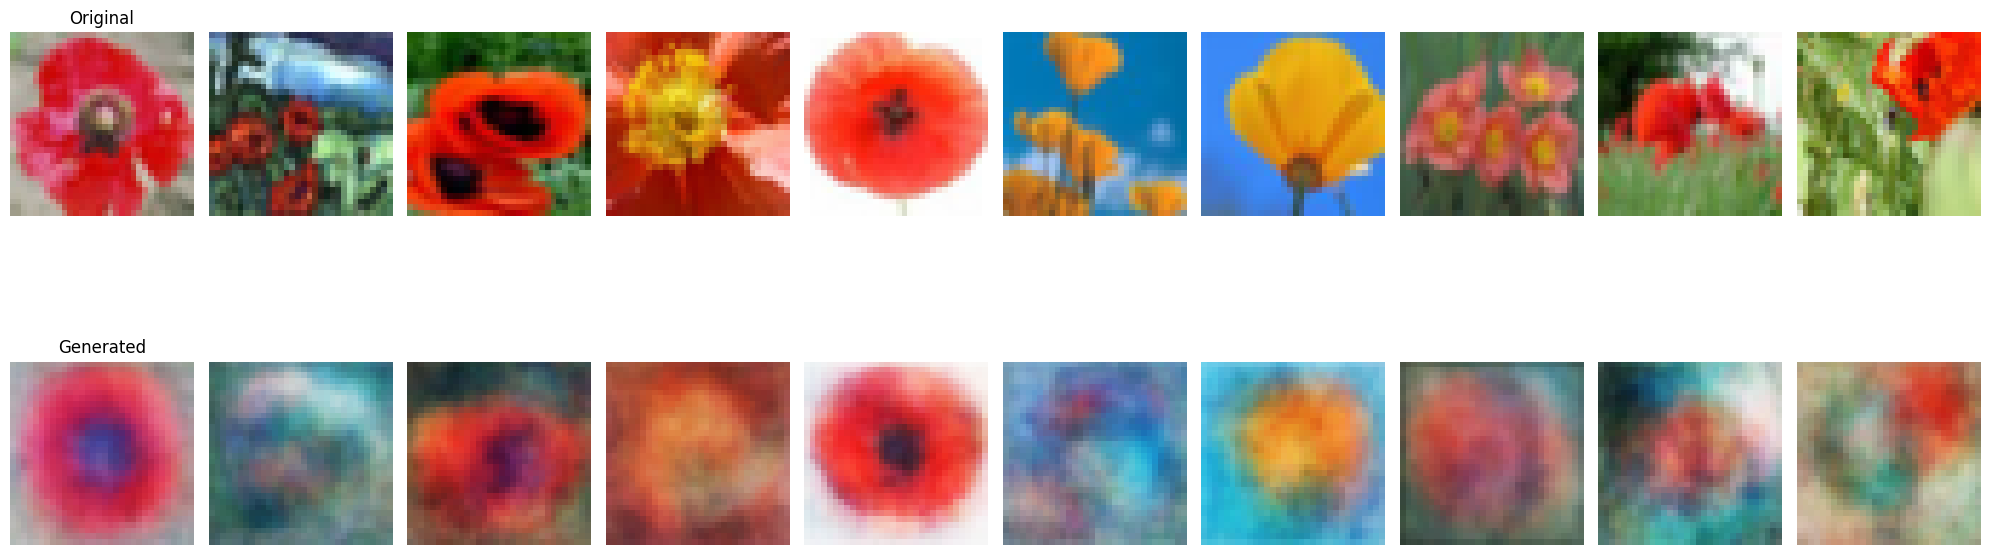

In [ ]:
mu, log_var = model.encode(x_test.reshape(-1, IMAGE_SIZE))
z = model.reparameterize(mu, log_var)
out = get_out_from_z(z)

number = 10
plt.figure(figsize=(20, 8))
for idx in range(number):
    ax = plt.subplot(2, number, idx + 1)
    plt.imshow(x_test[idx].reshape(IMAGE_ORIGINAL_SIZE))
    plt.axis('off')
    if idx == 0:
        ax.set_title('Original')

for idx in range(number):
    ax = plt.subplot(2, number, number + idx + 1)
    plt.imshow(out[idx].numpy())
    plt.axis('off')
    if idx == 0:
        ax.set_title('Generated')

plt.tight_layout()
plt.show()

## 2e) Construct New Dataset For Classification

In [13]:
# build real vs fake dataset for classification
ORIGINAL_LABEL = 1.0
FAKE_LABEL = 0.0

real_images = original_train_images
fake_images = generated_images

x = np.concatenate([real_images, fake_images], axis=0).astype(np.float32)
y = np.concatenate([
    np.ones(500, dtype=np.float32) * ORIGINAL_LABEL,
    np.zeros(500, dtype=np.float32) + FAKE_LABEL
], axis=0)

print('Dataset for classifier:', x.shape, y.shape)

Dataset for classifier: (1000, 32, 32, 3) (1000,)


## 2f) Construct and Train Deep Learning Classifier

In [14]:
x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=42)
x_test, x_val, y_test, y_val = train_test_split(x_temp, y_temp, train_size=0.5, random_state=42)

print(f"x_train: {x_train.shape}, y_train: {y_train.shape}")
print(f"x_val:   {x_val.shape}, y_val:   {y_val.shape}")
print(f"x_test:  {x_test.shape}, y_test:  {y_test.shape}")

x_train: (800, 32, 32, 3), y_train: (800,)
x_val:   (100, 32, 32, 3), y_val:   (100,)
x_test:  (100, 32, 32, 3), y_test:  (100,)


In [15]:
model_v1 = tf.keras.Sequential([
    tf.keras.layers.Conv2D(8, activation='relu', kernel_size=(3, 3), strides=(1, 1), padding='same', input_shape=(32, 32, 3)),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1, activation='sigmoid'),
])

In [16]:
model_v1.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [17]:
early_stopping_v1 = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3)
history_v1 = model_v1.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    callbacks=[early_stopping_v1]
)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5175 - loss: 0.6505 - val_accuracy: 0.7200 - val_loss: 0.5337
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7475 - loss: 0.5231 - val_accuracy: 0.8600 - val_loss: 0.4069
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8712 - loss: 0.4179 - val_accuracy: 0.9800 - val_loss: 0.2988
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9200 - loss: 0.3299 - val_accuracy: 0.9900 - val_loss: 0.2081
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9287 - loss: 0.2629 - val_accuracy: 0.9700 - val_loss: 0.1636
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9438 - loss: 0.2275 - val_accuracy: 0.9900 - val_loss: 0.1272
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9413 - loss: 0.1984 - val_accuracy: 0.9900 - val_loss: 0.1036
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9463 - loss: 0.1774 - val_accuracy: 0.9900 - val_loss:

In [18]:
loss_v1, accuracy_v1 = model_v1.evaluate(x_test, y_test)
print(f"Test Loss:     {loss_v1}")
print(f"Test Accuracy: {accuracy_v1}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9500 - loss: 0.1682 
Test Loss:     0.16820485889911652
Test Accuracy: 0.949999988079071


## 2g) Plot Training and Validation Losses Over Epochs

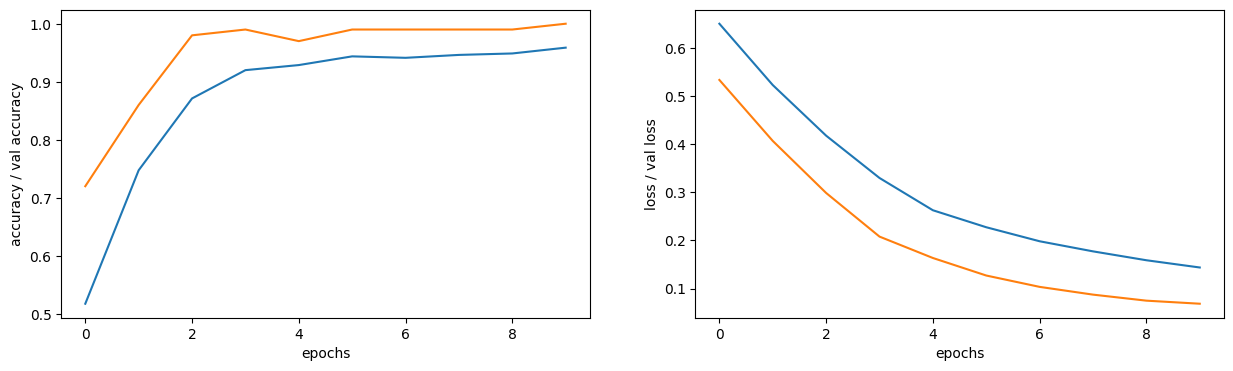

In [19]:
plt.figure(figsize=(15, 4))
plt.subplot(1, 2, 1)
plt.plot(history_v1.history['accuracy'])
plt.plot(history_v1.history['val_accuracy'])
plt.xlabel('epochs')
plt.ylabel('accuracy / val accuracy')

plt.subplot(1, 2, 2)
plt.plot(history_v1.history['loss'])
plt.plot(history_v1.history['val_loss'])
plt.xlabel('epochs')
plt.ylabel('loss / val loss')

plt.show()

Plot Accuracy dan Loss Analysis
1. Rapid learning: model memiliki peningkatan accuracy yg sangat cepat pada epoch awal dari 51.75% ke 87.12% di epoch 2
2. Loss convergence: training loss dan validation loss keduanya menurun secara konsisten. tidak ada fluktuasi besar yg mengindikasikan training yg stabil
3. Validation performance: validation accuracy mencapai 99-100% pada epoch-epoch akhir dengan validation loss yg sangat rendah (0.07)
4. No overfitting: gap antara training dan validation metrics sangat kecil

## 2h) Hyperparameter Tuning

In [20]:
model_v2 = tf.keras.Sequential([
    tf.keras.layers.Conv2D(16, activation='relu', kernel_size=(3, 3), strides=(1, 1), padding='same', input_shape=(32, 32, 3)),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid'),
])

model_v2.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stopping_v2 = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=3
)

history_v2 = model_v2.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    callbacks=[early_stopping_v2]
)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6625 - loss: 0.6075 - val_accuracy: 0.8500 - val_loss: 0.3896
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8288 - loss: 0.3873 - val_accuracy: 0.9700 - val_loss: 0.2345
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9187 - loss: 0.2709 - val_accuracy: 0.9700 - val_loss: 0.1781
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9362 - loss: 0.2143 - val_accuracy: 0.9800 - val_loss: 0.1174
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9538 - loss: 0.1604 - val_accuracy: 0.9700 - val_loss: 0.0997
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9625 - loss: 0.1360 - val_accuracy: 1.0000 - val_loss: 0.0725
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9638 - loss: 0.1358 - val_accuracy: 0.9700 - val_loss: 0.0908
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9712 - loss: 0.1082 - val_accuracy: 1.0000 - val_loss:

In [21]:
loss_v2, accuracy_v2 = model_v2.evaluate(x_test, y_test)
print(f"Test Loss:     {loss_v2}")
print(f"Test Accuracy: {accuracy_v2}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9900 - loss: 0.0859 
Test Loss:     0.0858951285481453
Test Accuracy: 0.9900000095367432


In [22]:
model_v3 = tf.keras.Sequential([
    tf.keras.layers.Conv2D(16, activation='relu', kernel_size=(3, 3), strides=(1, 1), padding='same', input_shape=(32, 32, 3)),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(16, activation='relu', kernel_size=(3, 3), strides=(1, 1), padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid'),
])

model_v3.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stopping_v3 = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=3, 
    restore_best_weights=True
)

history_v3 = model_v3.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    callbacks=[early_stopping_v3]
)

Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5987 - loss: 0.6071 - val_accuracy: 0.8700 - val_loss: 0.4054
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8600 - loss: 0.3691 - val_accuracy: 0.8700 - val_loss: 0.3100
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9212 - loss: 0.2361 - val_accuracy: 0.9800 - val_loss: 0.0868
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9362 - loss: 0.1713 - val_accuracy: 1.0000 - val_loss: 0.0489
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9675 - loss: 0.1172 - val_accuracy: 1.0000 - val_loss: 0.0305
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9800 - loss: 0.0737 - val_accuracy: 1.0000 - val_loss: 0.0155
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9850 - loss: 0.0586 - val_accuracy: 0.9900 - val_loss: 0.0464
Epoch 8/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9737 - loss: 0.0783 - val_accuracy: 0.9900 - val_loss

In [23]:
loss_v3, accuracy_v3 = model_v3.evaluate(x_test, y_test)
print(f"Test Loss:     {loss_v3}")
print(f"Test Accuracy: {accuracy_v3}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9900 - loss: 0.0466 
Test Loss:     0.04656904190778732
Test Accuracy: 0.9900000095367432


Analysis Hyperparameter Tuning

Model v1 (Baseline):
- Architecture: 1 Conv layer (8 filters) → MaxPool → Dense
- Result: Test accuracy 95%

Model v2 (Improvement 1):
- Changes: Increased filters to 16, added Dense hidden layer (16 units)
- Rationale: Lebih banyak filter untuk menangkap fitur yang lebih kompleks, hidden layer untuk non-linear combination
- Result: Test accuracy 99%, test loss turun dari 0.168 ke 0.086

Model v3 (Improvement 2):
- Changes: Menambah 1 Conv layer lagi, increased hidden Dense layers (32 units x 2), early stopping dengan restore_best_weights
- Rationale: Deeper network untuk hierarchical feature learning, lebih banyak neurons untuk representasi yang lebih rich
- Result: Test accuracy 99%, test loss turun lebih lanjut ke 0.047
- Best model dengan validation loss terendah di epoch 6 (0.0155)

## 2i) Test Classifier Model

In [24]:
loss, accuracy = model_v3.evaluate(x_test, y_test)
print(f"Test Loss:     {loss}")
print(f"Test Accuracy: {accuracy}")
print()


y_pred_probs = model_v3.predict(x_test)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()
y_true = y_test.astype(int)

print(classification_report(y_true, y_pred, target_names=['Fake (0)', 'Real (1)']))

precision = precision_score(y_true, y_pred)
recall    = recall_score(y_true, y_pred)
f1        = f1_score(y_true, y_pred)
auc       = roc_auc_score(y_true, y_pred_probs)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9900 - loss: 0.0466 
Test Loss:     0.04656904190778732
Test Accuracy: 0.9900000095367432

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
              precision    recall  f1-score   support

    Fake (0)       0.98      1.00      0.99        58
    Real (1)       1.00      0.98      0.99        42

    accuracy                           0.99       100
   macro avg       0.99      0.99      0.99       100
weighted avg       0.99      0.99      0.99       100

Precision: 1.0000
Recall:    0.9762
F1-Score:  0.9880
ROC-AUC:   1.0000


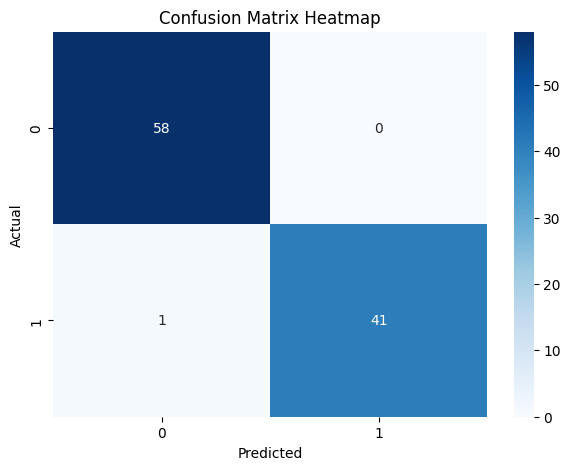

In [25]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix Heatmap")
plt.show()

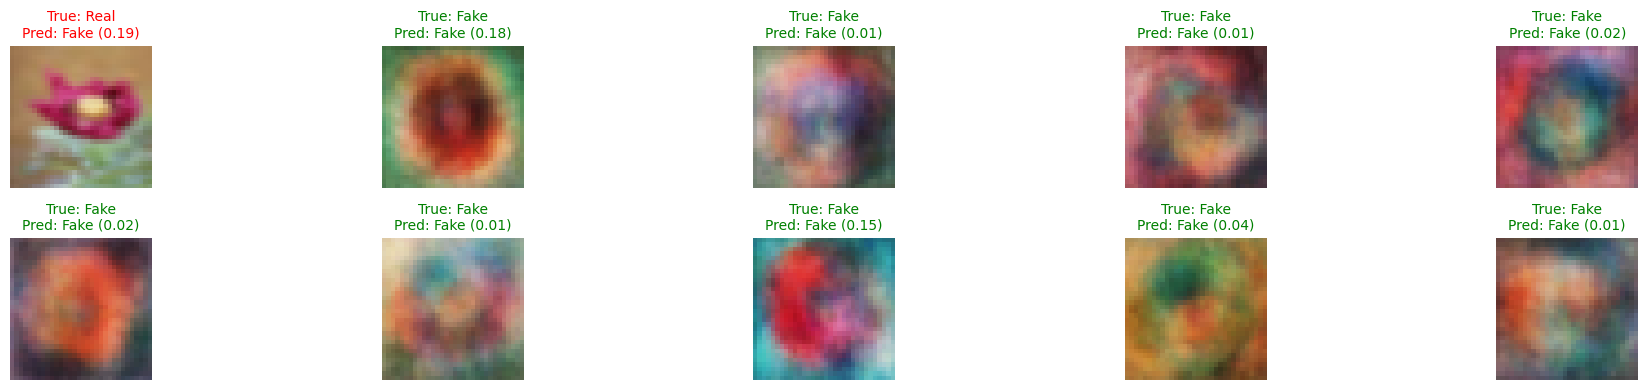

In [26]:
num_samples = 10

plt.figure(figsize=(20, 4))
for i in range(num_samples):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i])
    plt.axis('off')
    
    true_label = 'Real' if y_true[i] == 1 else 'Fake'
    pred_prob = y_pred_probs[i][0]
    pred_label = 'Real' if pred_prob > 0.5 else 'Fake'
    
    color = 'green' if y_pred[i] == y_true[i] else 'red'
    plt.title(f'True: {true_label}\nPred: {pred_label} ({pred_prob:.2f})', color=color, fontsize=10)

plt.tight_layout()
plt.show()

Performance Metrics:
- Test Accuracy: 99%
- Test Loss: 0.0466
- Precision: 1.0000 (100% dari prediksi "Real" adalah benar)
- Recall: 0.9762 (97.62% dari gambar real berhasil terdeteksi)
- F1-Score: 0.9880 (harmonic mean yang sangat tinggi)
- ROC-AUC: 1.0000 (perfect discrimination)

Classification Report Analysis:
- Fake (0): Precision 0.98, Recall 1.00 → Model sangat baik mendeteksi fake images (tidak ada false negative untuk fake)
- Real (1): Precision 1.00, Recall 0.98 → Model perfect dalam memprediksi real (tidak ada false positive), namun miss 1 real image

Confusion Matrix:
- True Negatives (Fake correctly classified): 58/58 (100%)
- True Positives (Real correctly classified): 41/42 (97.6%)
- False Negatives: 1 (1 real image classified as fake)
- False Positives: 0

Dapat disimpulkan bahwa model_v3 adalah model dengan accuracy terbaik.